# Лабораторная работа №2. Классификация и нейронные сети

**Датасет:** *Weather Dataset Rattle Package (WeatherAUS)*, Kaggle (`jsphyg/weather-dataset-rattle-package`).  
**Цель:** сравнить классические методы бинарной классификации из Scikit-Learn и нейронную сеть TensorFlow на задаче прогноза дождя на следующий день (`RainTomorrow`).

Задачи: подготовить данные, выполнить стратифицированное разбиение, настроить гиперпараметры, сравнить модели по Accuracy, Precision, Recall, F1 и ROC-AUC, а также визуализировать обучение нейросети в TensorBoard.


In [20]:
import os
import random
import warnings
from datetime import datetime
from pathlib import Path

# Кэш размещается в проекте: повторный запуск не зависит от глобального кэша пользователя.
os.environ["KAGGLEHUB_CACHE"] = str((Path("data") / "kagglehub_cache").resolve())

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, auc, classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
MAX_ROWS = 50_000       # None — использовать все строки; 50 000 ускоряет GridSearch и SVM
TEST_SIZE = 0.20
TUNING_SAMPLE = 20_000  # подвыборка train для подбора параметров

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
print(f"TensorFlow {tf.__version__}; seed = {RANDOM_STATE}")


TensorFlow 2.21.0; seed = 42


## 1. Загрузка и первичный анализ данных

Исходный набор содержит метеорологические наблюдения из Австралии: температуру, влажность, давление, облачность, направление и скорость ветра, факт дождя сегодня и целевой факт дождя завтра. `RainTomorrow` имеет пропуски в последних наблюдениях, поэтому строки без цели удаляются.


In [21]:
dataset_dir = Path(kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package"))
csv_path = dataset_dir / "weatherAUS.csv"
df = pd.read_csv(csv_path)

print(f"Размер исходного набора: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())
display(df.isna().mean().sort_values(ascending=False).head(12).to_frame("Доля пропусков"))

Размер исходного набора: 145,460 строк × 23 столбцов


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


,Доля пропусков
Sunshine,0.480098
Evaporation,0.431665
Cloud3pm,0.408071
Cloud9am,0.384216
Pressure9am,0.103568
Pressure3pm,0.103314
WindDir9am,0.072639
WindGustDir,0.070989
WindGustSpeed,0.070555
Humidity3pm,0.030984


## 2. Предобработка и разбиение

Дата разложена на год, месяц и день. Из признаков удалён `RISK_MM`: это величина осадков **на следующий день**, поэтому её использование означало бы утечку ответа. Для числовых признаков применяются медианная импутация и масштабирование; для категориальных — наиболее частое значение и one-hot-кодирование. Все преобразования включены в `Pipeline`, поэтому параметры преобразователей вычисляются только на обучающей части.


In [22]:
data = df.copy()
data = data.dropna(subset=["RainTomorrow"]).reset_index(drop=True)

date = pd.to_datetime(data.pop("Date"), errors="coerce")
data["Year"] = date.dt.year
data["Month"] = date.dt.month
data["Day"] = date.dt.day

LEAKAGE_COLUMNS = ["RISK_MM"]
data = data.drop(columns=LEAKAGE_COLUMNS, errors="ignore")
data["RainTomorrow"] = data["RainTomorrow"].map({"No": 0, "Yes": 1}).astype("int8")

if MAX_ROWS is not None and len(data) > MAX_ROWS:
    data, _ = train_test_split(
        data, train_size=MAX_ROWS, stratify=data["RainTomorrow"], random_state=RANDOM_STATE
    )
    data = data.reset_index(drop=True)

X = data.drop(columns="RainTomorrow")
y = data["RainTomorrow"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print(f"Используется строк: {len(data):,}; доля класса 'Yes': {y.mean():.2%}")
print(f"Train: {X_train.shape}; test: {X_test.shape}")
print(f"Числовых признаков: {len(numeric_features)}, категориальных: {len(categorical_features)}")
display(pd.DataFrame({"Тип": ["числовой", "категориальный"], "Количество": [len(numeric_features), len(categorical_features)]}))


Используется строк: 50,000; доля класса 'Yes': 22.42%
Train: (40000, 24); test: (10000, 24)
Числовых признаков: 19, категориальных: 5


,Тип,Количество
0,числовой,19
1,категориальный,5


## 3. Методы классификации и метрики

Исследуются четыре варианта наивного Байеса (Gaussian, Multinomial, Complement, Bernoulli), дерево решений, линейный дискриминантный анализ (LDA), SVM и kNN. Accuracy показывает общую долю верных ответов; Precision — надёжность положительного прогноза; Recall — долю найденных дождливых дней; F1 балансирует Precision и Recall; ROC-AUC оценивает ранжирование независимо от порога.


In [23]:
def make_preprocessor(scaler):
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", scaler)]), numeric_features),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categorical_features),
        ],
        remainder="drop",
    )

standard_preprocessor = make_preprocessor(StandardScaler())
nonnegative_preprocessor = make_preprocessor(MinMaxScaler())

models = {
    "GaussianNB": (GaussianNB(), standard_preprocessor, {"model__var_smoothing": [1e-10, 1e-9, 1e-8]}),
    "MultinomialNB": (MultinomialNB(), nonnegative_preprocessor, {"model__alpha": [0.1, 1.0, 3.0]}),
    "ComplementNB": (ComplementNB(), nonnegative_preprocessor, {"model__alpha": [0.1, 1.0, 3.0]}),
    "BernoulliNB": (BernoulliNB(), nonnegative_preprocessor, {"model__alpha": [0.1, 1.0, 3.0], "model__binarize": [0.0, 0.5]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE), standard_preprocessor,
        {"model__max_depth": [6, 12, None], "model__min_samples_leaf": [1, 10]},
    ),
    "LDA": (
        LinearDiscriminantAnalysis(solver="lsqr"), standard_preprocessor,
        {"model__shrinkage": [None, "auto"]},
    ),
    "SVM": (
        SVC(random_state=RANDOM_STATE), standard_preprocessor,
        {"model__C": [0.5, 1.0], "model__kernel": ["linear", "rbf"]},
    ),
    "kNN": (
        KNeighborsClassifier(), standard_preprocessor,
        {"model__n_neighbors": [5, 15], "model__weights": ["uniform", "distance"]},
    ),
}

def get_scores(estimator, features):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(features)[:, 1]
    return estimator.decision_function(features)

def evaluate_model(name, estimator, features, target):
    prediction = estimator.predict(features)
    scores = get_scores(estimator, features)
    return {
        "Модель": name,
        "Accuracy": accuracy_score(target, prediction),
        "Precision": precision_score(target, prediction, zero_division=0),
        "Recall": recall_score(target, prediction, zero_division=0),
        "F1-score": f1_score(target, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(target, scores),
    }, prediction, scores


## 4. Настройка гиперпараметров

Для каждого метода выполняется `GridSearchCV` с 3-fold стратифицированной кросс-валидацией. Критерий выбора — `ROC-AUC`; он устойчивее Accuracy для несбалансированного класса «дождь завтра». Чтобы время эксперимента было приемлемым, поиск проводится на стратифицированной части обучающей выборки, а итоговая лучшая конфигурация дообучается на всём train-наборе.


In [24]:
if len(X_train) > TUNING_SAMPLE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNING_SAMPLE, stratify=y_train, random_state=RANDOM_STATE
    )
else:
    X_tune, y_tune = X_train, y_train

best_estimators = {}
tuning_rows = []

for name, (model, preprocessor, grid) in models.items():
    pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(model))])
    search = GridSearchCV(
        pipeline, param_grid=grid, scoring="roc_auc", cv=3, n_jobs=-1, refit=True, verbose=1
    )
    search.fit(X_tune, y_tune)
    final_estimator = clone(search.best_estimator_).fit(X_train, y_train)
    best_estimators[name] = final_estimator
    tuning_rows.append({
        "Модель": name,
        "Лучшие параметры": str(search.best_params_),
        "CV ROC-AUC": search.best_score_,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("CV ROC-AUC", ascending=False)
display(tuning_results.round(4))


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Fitting 3 folds for each of 4 candidates, totalling 12 fits


,Модель,Лучшие параметры,CV ROC-AUC
5,LDA,{'model__shrinkage': None},0.8624
6,SVM,"{'model__C': 0.5, 'model__kernel': 'linear'}",0.8614
7,kNN,"{'model__n_neighbors': 15, 'model__weights': '...",0.8433
4,Decision Tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.8212
3,BernoulliNB,"{'model__alpha': 3.0, 'model__binarize': 0.5}",0.7963
1,MultinomialNB,{'model__alpha': 3.0},0.7487
2,ComplementNB,{'model__alpha': 3.0},0.7487
0,GaussianNB,{'model__var_smoothing': 1e-10},0.7335


## 5. Оценка классических моделей на тестовой выборке


In [25]:
metrics_rows, test_predictions, test_scores = [], {}, {}
for name, estimator in best_estimators.items():
    row, prediction, scores = evaluate_model(name, estimator, X_test, y_test)
    metrics_rows.append(row)
    test_predictions[name] = prediction
    test_scores[name] = scores

classic_results = pd.DataFrame(metrics_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(classic_results.round(4))


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.8498,0.7555,0.4880,0.5930,0.8721
1,LDA,0.8496,0.7269,0.5272,0.6112,0.8712
2,kNN,0.8420,0.7538,0.4384,0.5544,0.8591
3,Decision Tree,0.8432,0.7569,0.4429,0.5588,0.8443
4,BernoulliNB,0.7800,0.5082,0.5816,0.5424,0.8041
5,MultinomialNB,0.7814,0.5214,0.3037,0.3839,0.7497
6,ComplementNB,0.7012,0.4000,0.6655,0.4997,0.7497
7,GaussianNB,0.6563,0.3630,0.7061,0.4795,0.7455


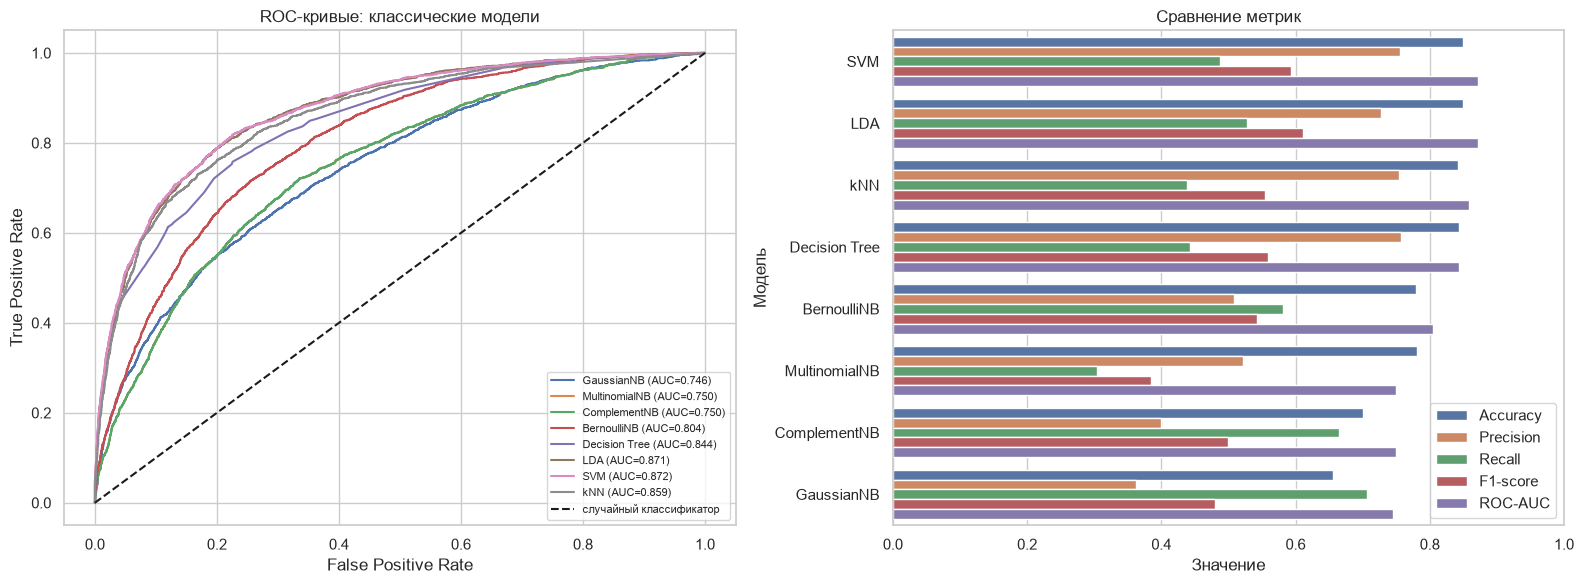

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, scores):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="случайный классификатор")
axes[0].set(title="ROC-кривые: классические модели", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[0].legend(fontsize=8)

metric_plot = classic_results.melt(id_vars="Модель", var_name="Метрика", value_name="Значение")
sns.barplot(data=metric_plot, x="Значение", y="Модель", hue="Метрика", ax=axes[1])
axes[1].set(title="Сравнение метрик", xlim=(0, 1))
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()


## 6. Нейронная сеть TensorFlow / Keras

Нейросеть получает те же подготовленные признаки. Архитектура состоит из полносвязных слоёв `Dense` с ReLU, Dropout-регуляризацией и выходного сигмоидального нейрона. Оптимизатор — Adam, функция потерь — binary cross-entropy. Экспериментируются число слоёв/нейронов, скорость обучения, batch size и число эпох. `EarlyStopping` восстанавливает веса с лучшим validation ROC-AUC.


In [27]:
# Нейронная сеть требует плотную матрицу; one-hot представление здесь уже dense.
nn_preprocessor = clone(standard_preprocessor)
X_train_nn = nn_preprocessor.fit_transform(X_train).astype("float32")
X_test_nn = nn_preprocessor.transform(X_test).astype("float32")


project_log_root = Path("logs").resolve()
if os.name == "nt" and not str(project_log_root).isascii():
    LOG_ROOT = Path(os.environ.get("PUBLIC", r"C:\Users\Public")) / "Documents" / "TensorBoardLogs" / "lab2_weather"
else:
    LOG_ROOT = project_log_root
LOG_ROOT.mkdir(parents=True, exist_ok=True)

def build_network(input_dim, hidden_units=(64, 32), dropout=0.20, learning_rate=1e-3):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,))])
    for units in hidden_units:
        model.add(tf.keras.layers.Dense(units, activation="relu"))
        model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )
    return model

experiments = [
    {"Название": "NN-1: 64-32, batch=128", "layers": (64, 32), "dropout": 0.20, "lr": 1e-3, "batch": 128, "epochs": 35},
    {"Название": "NN-2: 128-64-32, batch=128", "layers": (128, 64, 32), "dropout": 0.25, "lr": 1e-3, "batch": 128, "epochs": 35},
    {"Название": "NN-3: 128-64, batch=256", "layers": (128, 64), "dropout": 0.15, "lr": 5e-4, "batch": 256, "epochs": 45},
]


In [28]:
nn_histories, nn_models, nn_rows = {}, {}, []
for config in experiments:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    name = config["Название"]
    log_dir = LOG_ROOT / datetime.now().strftime("%Y%m%d-%H%M%S") / name.split(":")[0].replace(" ", "_")
    network = build_network(X_train_nn.shape[1], config["layers"], config["dropout"], config["lr"])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=str(log_dir), histogram_freq=1),
    ]
    history = network.fit(
        X_train_nn, y_train, validation_split=0.2, epochs=config["epochs"],
        batch_size=config["batch"], callbacks=callbacks, verbose=0,
    )
    probabilities = network.predict(X_test_nn, verbose=0).ravel()
    prediction = (probabilities >= 0.5).astype(int)
    nn_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1-score": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Эпох выполнено": len(history.history["loss"]),
        "Лог TensorBoard": str(log_dir),
    })
    nn_histories[name], nn_models[name] = history, network

nn_results = pd.DataFrame(nn_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(nn_results.round(4))


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC,Эпох выполнено,Лог TensorBoard
0,"NN-3: 128-64, batch=256",0.8627,0.7437,0.5914,0.6589,0.8906,32,C:\Users\Public\Documents\TensorBoardLogs\lab2...
1,"NN-1: 64-32, batch=128",0.8615,0.7552,0.5656,0.6468,0.8900,24,C:\Users\Public\Documents\TensorBoardLogs\lab2...
2,"NN-2: 128-64-32, batch=128",0.8610,0.7560,0.5611,0.6441,0.8879,19,C:\Users\Public\Documents\TensorBoardLogs\lab2...


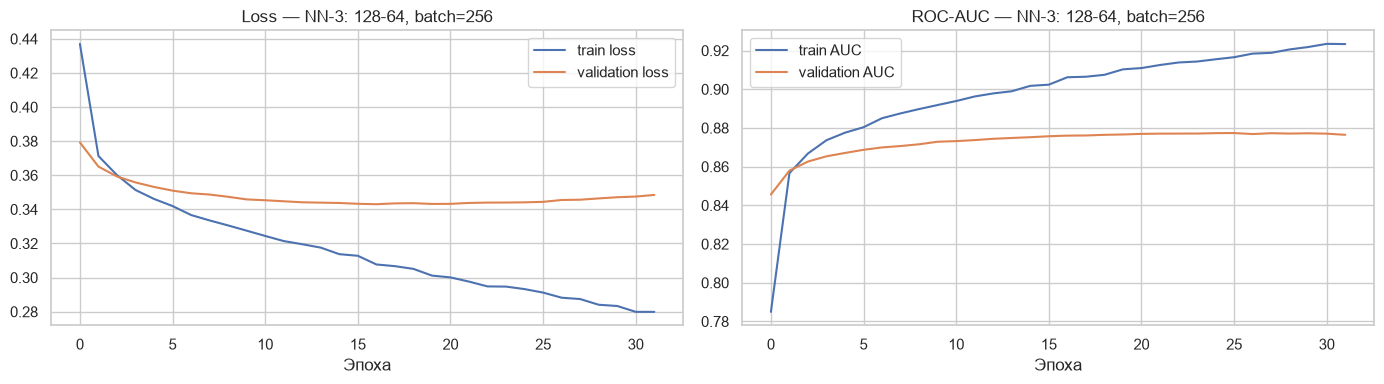

Логи TensorBoard сохранены в: C:\Users\Public\Documents\TensorBoardLogs\lab2_weather


In [29]:
best_nn_name = nn_results.iloc[0]["Модель"]
history = nn_histories[best_nn_name].history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history["loss"], label="train loss")
axes[0].plot(history["val_loss"], label="validation loss")
axes[0].set(title=f"Loss — {best_nn_name}", xlabel="Эпоха")
axes[0].legend()
axes[1].plot(history["auc"], label="train AUC")
axes[1].plot(history["val_auc"], label="validation AUC")
axes[1].set(title=f"ROC-AUC — {best_nn_name}", xlabel="Эпоха")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Логи TensorBoard сохранены в:", LOG_ROOT.resolve())


### TensorBoard

После или во время обучения запускаем в терминале `tensorboard --logdir "C:\Users\Public\Documents\TensorBoardLogs\lab2_weather"`.

Затем открываем в браузере адрес `http://localhost:6006`

На вкладке Scalars видны loss, accuracy, AUC, precision и recall для обучения и валидации.
На вкладке Histograms показывает распределения весов.

**accuracy за эпоху**

![accuracy за эпоху](tensorboard/Screenshot_1.png)

**auc за эпоху**

![AUC за эпоху](tensorboard/Screenshot_2.png)

**loss за эпоху**

![Loss за эпоху](tensorboard/Screenshot_3.png)

**precision за эпоху**

![precision за эпоху](tensorboard/Screenshot_4.png)

**recall за эпоху**

![recall за эпоху](tensorboard/Screenshot_5.png)

**Эволюция accuracy по итерациям**

![**Эволюция Accuracy по итерациям**](tensorboard/Screenshot_6.png)

**Эволюция auc по итерациям**

![**Эволюция auc по итерациям**](tensorboard/Screenshot_7.png)

**Эволюция loss по итерациям**

![**Эволюция loss по итерациям**](tensorboard/Screenshot_8.png)

**Эволюция precision по итерациям**

![**Эволюция precision по итерациям**](tensorboard/Screenshot_9.png)

**Эволюция recall по итерациям**

![**Эволюция recall по итерациям**](tensorboard/Screenshot_10.png)

**Гистограммы с распределением весов**

![Гистограммы с распределением весов](tensorboard/Screenshot_11.png)


## 7. Итоговое сравнение и вывод


In [30]:
best_nn = nn_models[best_nn_name]
best_nn_probabilities = best_nn.predict(X_test_nn, verbose=0).ravel()
best_nn_prediction = (best_nn_probabilities >= 0.5).astype(int)
nn_summary = pd.DataFrame([{
    "Модель": "TensorFlow: " + best_nn_name,
    "Accuracy": accuracy_score(y_test, best_nn_prediction),
    "Precision": precision_score(y_test, best_nn_prediction, zero_division=0),
    "Recall": recall_score(y_test, best_nn_prediction, zero_division=0),
    "F1-score": f1_score(y_test, best_nn_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, best_nn_probabilities),
}])

all_results = pd.concat([classic_results, nn_summary], ignore_index=True).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(all_results.round(4))


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,"TensorFlow: NN-3: 128-64, batch=256",0.8627,0.7437,0.5914,0.6589,0.8906
1,SVM,0.8498,0.7555,0.4880,0.5930,0.8721
2,LDA,0.8496,0.7269,0.5272,0.6112,0.8712
3,kNN,0.8420,0.7538,0.4384,0.5544,0.8591
4,Decision Tree,0.8432,0.7569,0.4429,0.5588,0.8443
5,BernoulliNB,0.7800,0.5082,0.5816,0.5424,0.8041
6,MultinomialNB,0.7814,0.5214,0.3037,0.3839,0.7497
7,ComplementNB,0.7012,0.4000,0.6655,0.4997,0.7497
8,GaussianNB,0.6563,0.3630,0.7061,0.4795,0.7455


## Заключение

В работе были подготовлены метеоданные, предотвращена утечка целевого признака, обучены и настроены восемь классических классификаторов и несколько архитектур нейронной сети. Лучшей моделью по ROC-AUC стала модель TensorFlow на нейросетях, однако в зависимости от задачи прогнозирования выбор метрики для оценивания может быть разный: ROC-AUC характеризует качество ранжирования, а Precision/Recall и F1 помогают выбрать рабочий порог для прикладной задачи прогноза дождя.
